#Importing the dependencies

In [1]:
import numpy as np
import pandas as pd


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 1. Understanding the Dataset

Used to display, all the columns in a DataFrame

In [3]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

In [ ]:
data = pd.read_excel('/content/drive/MyDrive/Datamites_proj_3_Flight_fare/Flight_Fare.xlsx')

In [ ]:
data.head(15)

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302
5,SpiceJet,24/06/2019,Kolkata,Banglore,CCU → BLR,09:00,11:25,2h 25m,non-stop,No info,3873
6,Jet Airways,12/03/2019,Banglore,New Delhi,BLR → BOM → DEL,18:55,10:25 13 Mar,15h 30m,1 stop,In-flight meal not included,11087
7,Jet Airways,01/03/2019,Banglore,New Delhi,BLR → BOM → DEL,08:00,05:05 02 Mar,21h 5m,1 stop,No info,22270
8,Jet Airways,12/03/2019,Banglore,New Delhi,BLR → BOM → DEL,08:55,10:25 13 Mar,25h 30m,1 stop,In-flight meal not included,11087
9,Multiple carriers,27/05/2019,Delhi,Cochin,DEL → BOM → COK,11:25,19:15,7h 50m,1 stop,No info,8625


Understanding the shape of the data

In [ ]:
data.shape

(10683, 11)

Column names

In [ ]:
data.columns

Index(['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route',
       'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops',
       'Additional_Info', 'Price'],
      dtype='object')

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


Statistical summary

In [ ]:
data.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


Statistical summary for categorical columns

In [ ]:
data.describe(include='O')

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info
count,10683,10683,10683,10683,10682,10683,10683,10683,10682,10683
unique,12,44,5,6,128,222,1343,368,5,10
top,Jet Airways,18/05/2019,Delhi,Cochin,DEL → BOM → COK,18:55,19:00,2h 50m,1 stop,No info
freq,3849,504,4537,4537,2376,233,423,550,5625,8345


Understanding the categories present in each Categorical column

In [ ]:
print(data['Airline'].value_counts())
print('-'*100)
print(data['Source'].value_counts())
print('-'*100)
print(data['Destination'].value_counts())
print('-'*100)
print(data['Total_Stops'].value_counts())

print('-'*100)
print(data['Additional_Info'].value_counts())

Airline
Jet Airways                          3849
IndiGo                               2053
Air India                            1752
Multiple carriers                    1196
SpiceJet                              818
Vistara                               479
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64
----------------------------------------------------------------------------------------------------
Source
Delhi       4537
Kolkata     2871
Banglore    2197
Mumbai       697
Chennai      381
Name: count, dtype: int64
----------------------------------------------------------------------------------------------------
Destination
Cochin       4537
Banglore     2871
Delhi        1265
New Delhi     932
Hyderabad     697
Kolkata       381
Name: count, dtype: in

# 2. Data cleaning & Wrangling

Checking missing values

In [ ]:
# Check missing values in each column
data.isnull().sum()

,0
Airline,0
Date_of_Journey,0
Source,0
Destination,0
Route,1
Dep_Time,0
Arrival_Time,0
Duration,0
Total_Stops,1
Additional_Info,0


In [ ]:
data[data['Route'].isnull() | data['Total_Stops'].isnull()]

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
9039,Air India,6/05/2019,Delhi,Cochin,NaN,09:45,09:25 07 May,23h 40m,NaN,No info,7480


In [ ]:
data.dropna(subset=['Route', 'Total_Stops'], inplace=True)

Checking duplicate rows (total sum of duplicate records)

In [ ]:
# Check number of duplicate rows
data.duplicated().sum()

np.int64(220)

Looking at the duplicate records

In [ ]:
data[data.duplicated(keep=False)].sort_values(by=list(data.columns))

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
6321,Air India,01/03/2019,Banglore,New Delhi,BLR → BOM → AMD → DEL,08:50,23:55 02 Mar,39h 5m,2 stops,No info,17135
9848,Air India,01/03/2019,Banglore,New Delhi,BLR → BOM → AMD → DEL,08:50,23:55 02 Mar,39h 5m,2 stops,No info,17135
572,Air India,03/03/2019,Banglore,New Delhi,BLR → DEL,21:10,23:55,2h 45m,non-stop,No info,7591
8168,Air India,03/03/2019,Banglore,New Delhi,BLR → DEL,21:10,23:55,2h 45m,non-stop,No info,7591
1495,Air India,1/04/2019,Kolkata,Banglore,CCU → DEL → COK → BLR,10:00,01:20 02 Apr,15h 20m,2 stops,No info,10408
9913,Air India,1/04/2019,Kolkata,Banglore,CCU → DEL → COK → BLR,10:00,01:20 02 Apr,15h 20m,2 stops,No info,10408
4603,Air India,1/05/2019,Kolkata,Banglore,CCU → DEL → COK → BLR,10:00,13:45 02 May,27h 45m,2 stops,No info,15164
5042,Air India,1/05/2019,Kolkata,Banglore,CCU → DEL → COK → BLR,10:00,13:45 02 May,27h 45m,2 stops,No info,15164
6377,Air India,1/05/2019,Kolkata,Banglore,CCU → DEL → COK → BLR,10:00,13:45 02 May,27h 45m,2 stops,No info,15164
3598,Air India,1/05/2019,Kolkata,Banglore,CCU → GAU → DEL → BLR,09:50,08:55 02 May,23h 5m,2 stops,No info,13227


Duplicate records were identified and removed to prevent repeated observations from introducing bias during model training.

In [ ]:
data.drop_duplicates(inplace=True)

In [ ]:
data.duplicated().sum()

np.int64(0)

In [ ]:
data.to_excel(
    '/content/drive/MyDrive/Datamites_proj_3_Flight_fare/update_1.xlsx',
    index=False
)

In [ ]:
update_1 = pd.read_excel('/content/drive/MyDrive/Datamites_proj_3_Flight_fare/update_1.xlsx')
update_1.head(15)

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302
5,SpiceJet,24/06/2019,Kolkata,Banglore,CCU → BLR,09:00,11:25,2h 25m,non-stop,No info,3873
6,Jet Airways,12/03/2019,Banglore,New Delhi,BLR → BOM → DEL,18:55,10:25 13 Mar,15h 30m,1 stop,In-flight meal not included,11087
7,Jet Airways,01/03/2019,Banglore,New Delhi,BLR → BOM → DEL,08:00,05:05 02 Mar,21h 5m,1 stop,No info,22270
8,Jet Airways,12/03/2019,Banglore,New Delhi,BLR → BOM → DEL,08:55,10:25 13 Mar,25h 30m,1 stop,In-flight meal not included,11087
9,Multiple carriers,27/05/2019,Delhi,Cochin,DEL → BOM → COK,11:25,19:15,7h 50m,1 stop,No info,8625


In [ ]:
update_1.duplicated().sum()

np.int64(0)

Date_of_Journey — Data Wrangling

In [ ]:
# Convert Date_of_Journey to datetime format
update_1['Date_of_Journey'] = pd.to_datetime(
    update_1['Date_of_Journey'],
    format='%d/%m/%Y'
)

# Extract day and month
update_1['Journey_Day'] = update_1['Date_of_Journey'].dt.day
update_1['Journey_Month'] = update_1['Date_of_Journey'].dt.month

# Drop the original date column
update_1.drop('Date_of_Journey', axis=1, inplace=True)

Dep_Time &	Arrival_Time -- Data Wrangling

In [ ]:
# Extract departure hour
update_1['Dep_Hour'] = update_1['Dep_Time'].str.split(':').str[0].astype(int)

# Extract arrival hour
update_1['Arrival_Hour'] = update_1['Arrival_Time'].str.split(':').str[0].astype(int)

# Drop the original time columns
update_1.drop(['Dep_Time', 'Arrival_Time'], axis=1, inplace=True)

Duration → Minutes -- Data Wrangling

In [ ]:
# Convert Duration into total minutes
def duration_to_minutes(duration):
    hours = 0
    minutes = 0

    if 'h' in duration:
        hours = int(duration.split('h')[0])

    if 'm' in duration:
        minutes = int(duration.split('m')[0].split()[-1])

    return hours * 60 + minutes

update_1['Duration_Minutes'] = update_1['Duration'].apply(duration_to_minutes)

# Drop the original Duration column
update_1.drop('Duration', axis=1, inplace=True)

Total_Stops → Number of Stops -- Data Wrangling

In [ ]:
# Convert Total_Stops into numerical values
update_1['Total_Stops'] = (
    update_1['Total_Stops']
    .str.extract(r'(\d+)')[0]
    .fillna(0)
    .astype(int)
)

In [ ]:
update_1.head()

,Airline,Source,Destination,Route,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Dep_Hour,Arrival_Hour,Duration_Minutes
0,IndiGo,Banglore,New Delhi,BLR → DEL,0,No info,3897,24,3,22,1,170
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,2,No info,7662,1,5,5,13,445
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,2,No info,13882,9,6,9,4,1140
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,1,No info,6218,12,5,18,23,325
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,1,No info,13302,1,3,16,21,285


Drop Route column

In [ ]:
update_1.drop('Route', axis=1, inplace=True)

We already have:
Total_Stops
,Source
,Destination

Route contains sequences such as:

CCU → IXR → BBI → BLR


It's a high-cardinality categorical feature and would require additional feature engineering/encoding. Since Total_Stops already captures an important part of the route complexity, we'll drop it for this project.

Drop Additional_Info column

In [ ]:
update_1['Additional_Info'].value_counts(normalize=True) * 100

,proportion
Additional_Info,
No info,78.206844
In-flight meal not included,18.409482
No check-in baggage included,3.039572
1 Long layover,0.181610
Change airports,0.066909
Business class,0.038234
No Info,0.028675
1 Short layover,0.009558
Red-eye flight,0.009558


In [ ]:
update_1.drop('Additional_Info', axis=1, inplace=True)

The feature is dominated by "No info" and therefore provides limited useful information for predicting fare, So we just drop it. And we found that approximately 80% of the values are "No info".

Check our current dataset

In [ ]:
print(update_1.head())

print(update_1.shape)

       Airline    Source Destination  Total_Stops  Price  Journey_Day  \
0       IndiGo  Banglore   New Delhi            0   3897           24   
1    Air India   Kolkata    Banglore            2   7662            1   
2  Jet Airways     Delhi      Cochin            2  13882            9   
3       IndiGo   Kolkata    Banglore            1   6218           12   
4       IndiGo  Banglore   New Delhi            1  13302            1   

   Journey_Month  Dep_Hour  Arrival_Hour  Duration_Minutes  
0              3        22             1               170  
1              5         5            13               445  
2              6         9             4              1140  
3              5        18            23               325  
4              3        16            21               285  
(10462, 10)


In [ ]:
update_1.to_excel(
    '/content/drive/MyDrive/Datamites_proj_3_Flight_fare/update_2.xlsx',
    index=False
)

In [ ]:
update_2 = pd.read_excel('/content/drive/MyDrive/Datamites_proj_3_Flight_fare/update_2.xlsx')
update_2.head(15)

,Airline,Source,Destination,Total_Stops,Price,Journey_Day,Journey_Month,Dep_Hour,Arrival_Hour,Duration_Minutes
0,IndiGo,Banglore,New Delhi,0,3897,24,3,22,1,170
1,Air India,Kolkata,Banglore,2,7662,1,5,5,13,445
2,Jet Airways,Delhi,Cochin,2,13882,9,6,9,4,1140
3,IndiGo,Kolkata,Banglore,1,6218,12,5,18,23,325
4,IndiGo,Banglore,New Delhi,1,13302,1,3,16,21,285
5,SpiceJet,Kolkata,Banglore,0,3873,24,6,9,11,145
6,Jet Airways,Banglore,New Delhi,1,11087,12,3,18,10,930
7,Jet Airways,Banglore,New Delhi,1,22270,1,3,8,5,1265
8,Jet Airways,Banglore,New Delhi,1,11087,12,3,8,10,1530
9,Multiple carriers,Delhi,Cochin,1,8625,27,5,11,19,470


## 📊 3. Exploratory Data Analysis (EDA)

In [ ]:
# let's import the visualization libraries.

import matplotlib.pyplot as plt
import seaborn as sns

📈 Chart 1: Distribution of Flight Prices

Why this chart?

We want to understand how flight prices are distributed across the dataset.

A histogram helps us identify:

Whether prices are normally distributed or skewed.
The most common price ranges.
Potential extreme values (very expensive flights).

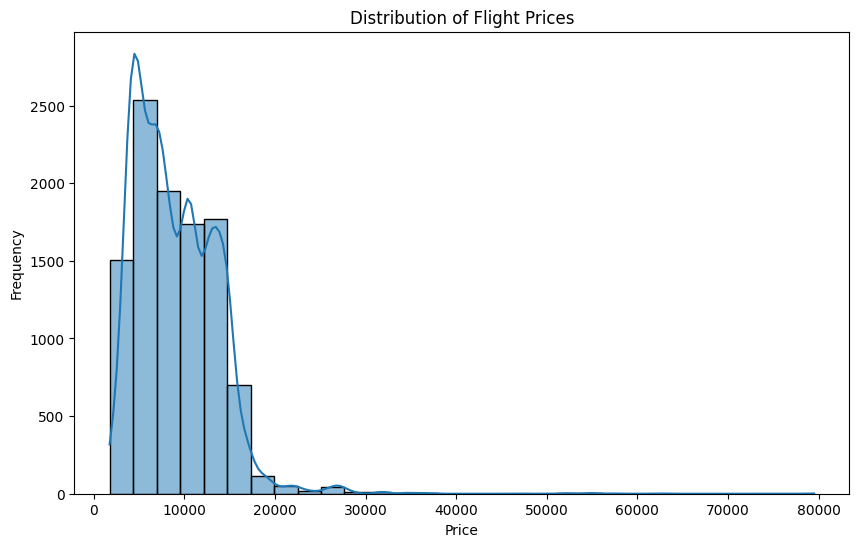

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(data=update_2, x='Price', bins=30, kde=True)

plt.title('Distribution of Flight Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')

plt.show()

Insights from the Chart 1:

The flight price distribution is right-skewed, with most fares concentrated approximately between ₹5,000 and ₹15,000. A few high-priced flights create a long right tail, indicating the presence of expensive fare outliers.

📊 Chart 2: Average Flight Price by Airline

Why this chart?

Different airlines may have different pricing strategies, service levels, and flight characteristics.

A bar chart allows us to compare the average flight price across airlines.

This is useful because Airline is one of our categorical features, and Price is our target variable..

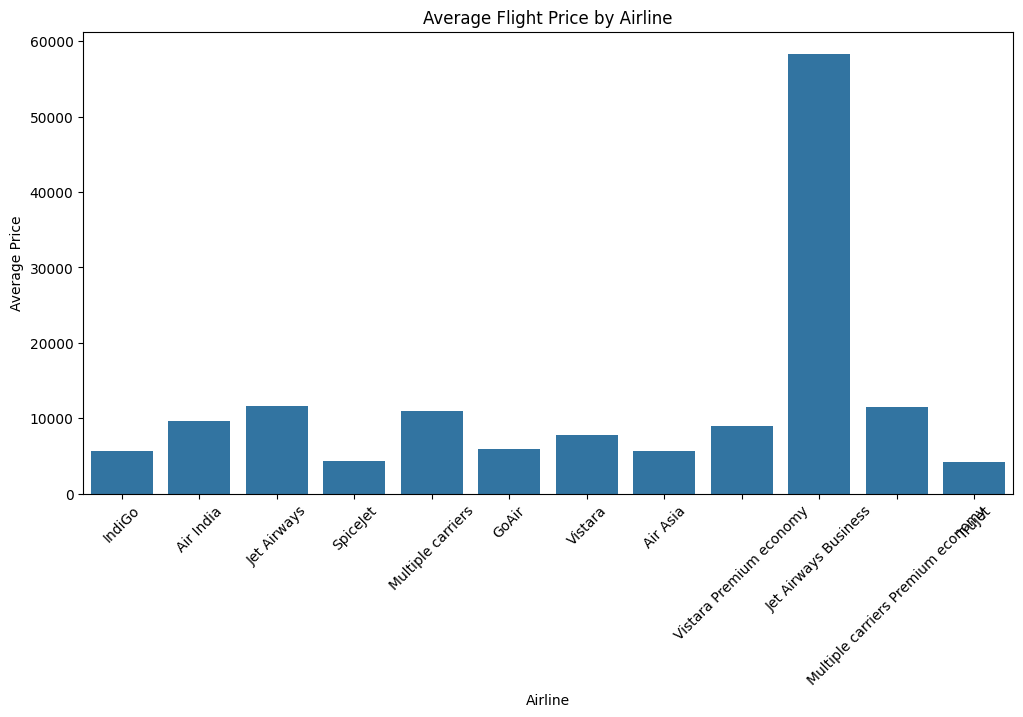

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=update_2,
    x='Airline',
    y='Price',
    estimator='mean',
    errorbar=None
)

plt.title('Average Flight Price by Airline')
plt.xlabel('Airline')
plt.ylabel('Average Price')

plt.xticks(rotation=45)

plt.show()

Insights from the chart:

The chart shows noticeable differences in average flight prices across airlines. Jet Airways Business has the highest average fare, while Trujet and SpiceJet have relatively lower average fares. However, these differences may also be influenced by factors such as flight duration, route, and number of stops.

📉 Chart 3: Flight Duration vs. Price

Why this chart?

We previously identified Duration_Minutes as an important numerical feature.

We want to investigate whether flight duration has a relationship with flight price.

A scatter plot is appropriate because:

Duration_Minutes is numerical.
Price is numerical.
We can observe the relationship between individual observations.
We can identify clusters and potential outliers.

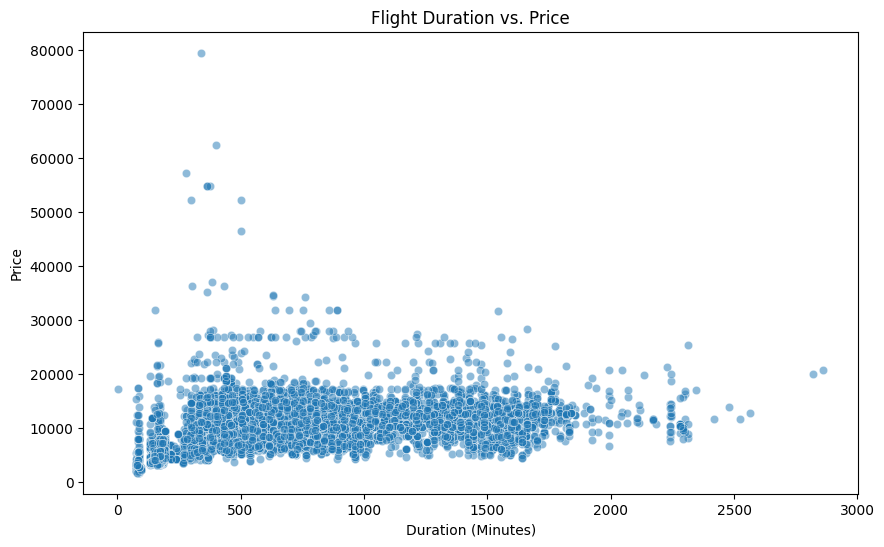

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=update_2,
    x='Duration_Minutes',
    y='Price',
    alpha=0.5
)

plt.title('Flight Duration vs. Price')
plt.xlabel('Duration (Minutes)')
plt.ylabel('Price')

plt.show()

Insights from the Chart 3:

The scatter plot does not show a strong linear relationship between flight duration and price. Most flights are concentrated within the ₹5,000–₹15,000 price range across different durations. Some high-priced outliers are observed, particularly at shorter durations. This suggests that flight duration alone may not be sufficient to explain flight prices, and other factors such as airline, route, stops, and departure time may also influence the fare.

📊 Chart 4: Total Stops vs. Flight Price

Why this chart?

To understand whether the number of stops affects flight prices and to compare fare distributions across different stop categories.

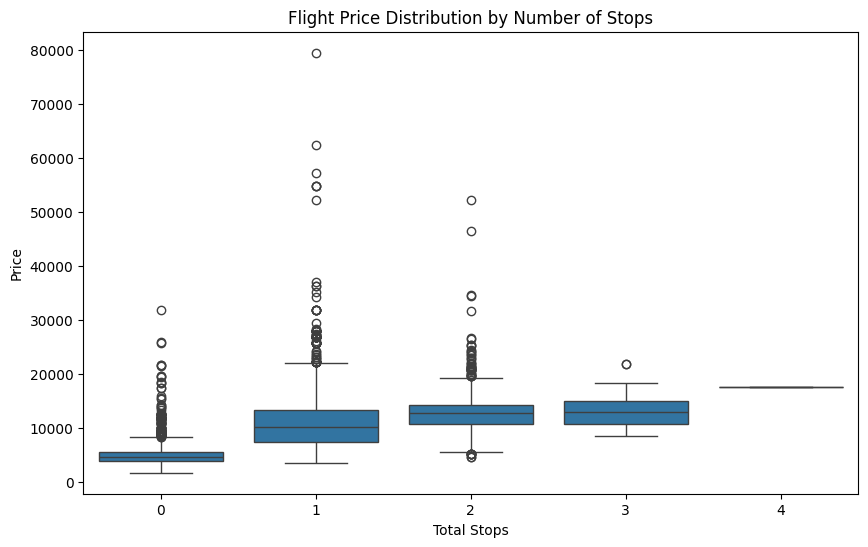

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=update_2,
    x='Total_Stops',
    y='Price'
)

plt.title('Flight Price Distribution by Number of Stops')
plt.xlabel('Total Stops')
plt.ylabel('Price')
plt.show()

Insights from Chart 4:

Flight prices generally increase as the number of stops increases from 0 to 3, with direct flights offering the lowest median price of approximately 5,000.

Interestingly, 1-stop flights exhibit the highest price volatility, containing extreme upper outliers that peak near 80,000.

While routes with 2 and 3 stops show progressively higher baseline median prices, their extreme price spikes are less severe than those found in the 1-stop category.

Flights with 4 stops appear to have a very limited dataset, showing a flat pricing structure around 17,500.

📊 Chart 5: Average Price by Source and Destination

Why this chart?

To identify how flight routes influence average ticket prices by comparing different source–destination combinations

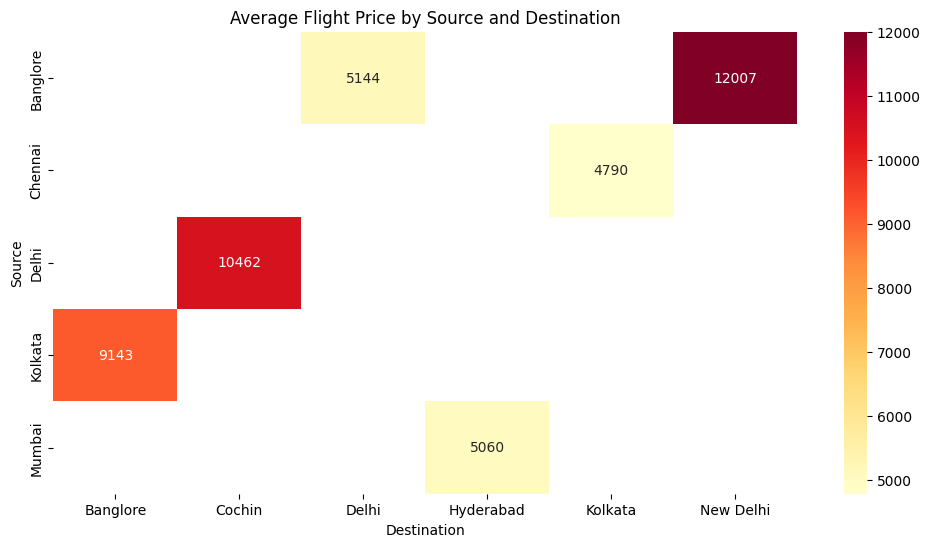

In [ ]:
price_matrix = update_2.pivot_table(
    values='Price',
    index='Source',
    columns='Destination',
    aggfunc='mean'
)

plt.figure(figsize=(12, 6))

sns.heatmap(
    price_matrix,
    annot=True,
    fmt='.0f',
    cmap='YlOrRd'
)

plt.title('Average Flight Price by Source and Destination')
plt.xlabel('Destination')
plt.ylabel('Source')
plt.show()

Insights from Chart 5:

The heatmap shows noticeable differences in average flight prices across source–destination combinations. For example, the Bangalore–New Delhi route has an average fare of approximately ₹12,007, while the Mumbai–Hyderabad route has an average fare of approximately ₹5,060.

This indicates that the travel route may influence flight prices. However, these differences may also be affected by factors such as airline, duration, and number of stops.

📊 Chart 6: Average Price by Departure Hour

Why this chart?

To examine whether departure time is associated with changes in average flight prices.

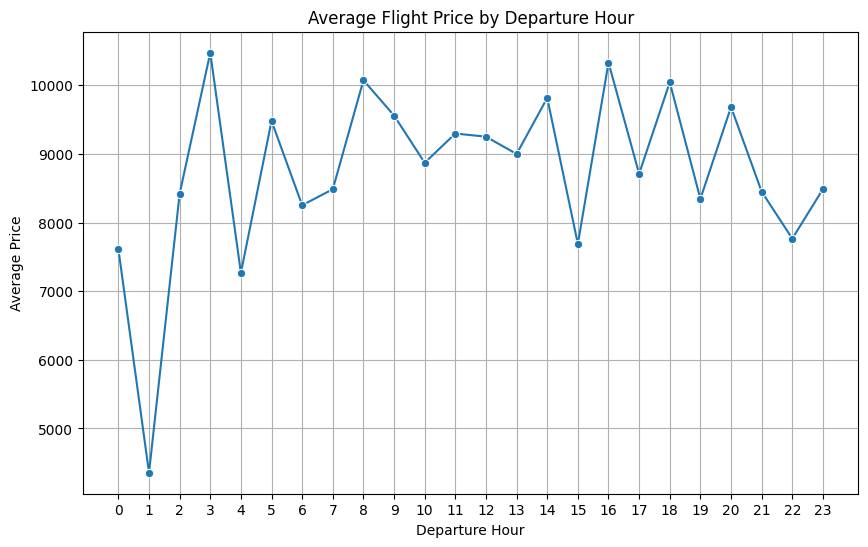

In [ ]:
hourly_price = update_2.groupby('Dep_Hour')['Price'].mean().reset_index()

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=hourly_price,
    x='Dep_Hour',
    y='Price',
    marker='o'
)

plt.title('Average Flight Price by Departure Hour')
plt.xlabel('Departure Hour')
plt.ylabel('Average Price')
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

Insights from Chart 6:

The line chart reveals that flight prices fluctuate drastically depending on the departure hour, highlighting clear windows for optimal savings. The cheapest time to fly is at 1:00 AM (01:00), where average prices plummet to an absolute low of roughly 4,300.

Conversely, flights departing during peak early morning hours around 3:00 AM command the highest average premium, soaring past 10,000. Throughout the rest of the day (from 8:00 AM to 8:00 PM), pricing exhibits a highly volatile zigzag pattern, consistently bouncing between secondary peaks near 10,000 and sharper valleys around 15:00 and 19:00.

## 4. Hypothesis Testing

**Hypothesis Testing – 1**

1. State Your Research Hypothesis


Null Hypothesis (H₀):
There is no significant linear relationship between Duration_Minutes and Price.

Alternative Hypothesis (H₁):
There is a significant linear relationship between Duration_Minutes and Price.

2. Perform an Appropriate Statistical Test

We will use the Pearson correlation test.

In [ ]:
from scipy import stats

# Pearson correlation test between Duration and Price
duration = update_2['Duration_Minutes']
price = update_2['Price']

corr, p_value = stats.pearsonr(duration, price)

print("Correlation coefficient:", corr)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: There is a significant linear relationship between Duration and Price.")
else:
    print("Fail to reject H0: There is no significant linear relationship between Duration and Price.")

Correlation coefficient: 0.5017579376022409
P-value: 0.0
Reject H0: There is a significant linear relationship between Duration and Price.


3. Which Statistical Test Have You Done to Obtain the P-Value?

A Pearson correlation test was performed to measure the strength and statistical significance of the linear relationship between Duration_Minutes and Price.

4. Why Did You Choose This Specific Statistical Test?

Pearson correlation was chosen because both Duration_Minutes and Price are numerical variables, and the objective is to determine whether there is a
statistically significant linear relationship between them. The correlation coefficient indicates the direction and strength of the relationship,
while the p-value determines whether the observed relationship is statistically significant or could have occurred by chance.

**Hypothesis Testing – 2**

Relationship between Number of Stops and Flight Price
1. State Your Research Hypothesis

Null Hypothesis (H₀):
There is no significant difference in the mean flight prices among flights with different numbers of stops.

Alternative Hypothesis (H₁):
There is a significant difference in the mean flight prices among flights with different numbers of stops.

2. Perform an Appropriate Statistical Test

We will use a One-Way ANOVA test.

In [ ]:
from scipy import stats

# Create groups based on the number of stops
groups = [
    group['Price'].values
    for name, group in update_2.groupby('Total_Stops')
]

# Perform One-Way ANOVA
f_statistic, p_value = stats.f_oneway(*groups)

print("F-statistic:", f_statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: There is a significant difference in mean flight prices among different stop categories.")
else:
    print("Fail to reject H0: There is no significant difference in mean flight prices among different stop categories.")

F-statistic: 1722.5724443006973
P-value: 0.0
Reject H0: There is a significant difference in mean flight prices among different stop categories.


3. Which Statistical Test Have You Done to Obtain the P-Value?

A One-Way ANOVA (Analysis of Variance) test was performed to determine whether there is a statistically significant difference in mean flight prices among flights with different numbers of stops.



4. Why Did You Choose This Specific Statistical Test?

One-Way ANOVA was chosen because Total_Stops is a categorical/grouping variable with more than two groups, while Price is a numerical variable. The objective is to determine whether the mean flight price differs significantly across these stop categories. ANOVA provides a p-value that helps determine whether the observed differences in mean prices are statistically significant.

## 5. Feature Engineering & Data Preprocessing

In [ ]:
update_2.head(15)

,Airline,Source,Destination,Total_Stops,Price,Journey_Day,Journey_Month,Dep_Hour,Arrival_Hour,Duration_Minutes
0,IndiGo,Banglore,New Delhi,0,3897,24,3,22,1,170
1,Air India,Kolkata,Banglore,2,7662,1,5,5,13,445
2,Jet Airways,Delhi,Cochin,2,13882,9,6,9,4,1140
3,IndiGo,Kolkata,Banglore,1,6218,12,5,18,23,325
4,IndiGo,Banglore,New Delhi,1,13302,1,3,16,21,285
5,SpiceJet,Kolkata,Banglore,0,3873,24,6,9,11,145
6,Jet Airways,Banglore,New Delhi,1,11087,12,3,18,10,930
7,Jet Airways,Banglore,New Delhi,1,22270,1,3,8,5,1265
8,Jet Airways,Banglore,New Delhi,1,11087,12,3,8,10,1530
9,Multiple carriers,Delhi,Cochin,1,8625,27,5,11,19,470


1. Categorical encoding - One-Hot Encoding

Why One-Hot Encoding?

Because Airline, Source, and Destination do not have an inherent numerical order.

In [ ]:
# Categorical columns to encode
categorical_columns = ['Airline', 'Source', 'Destination']

# Perform One-Hot Encoding
update_encoded = pd.get_dummies(
    update_2,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

# Check the updated dataset
update_encoded.head()

,Total_Stops,Price,Journey_Day,Journey_Month,Dep_Hour,Arrival_Hour,Duration_Minutes,Airline_Air India,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Jet Airways Business,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,Airline_Vistara,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,0,3897,24,3,22,1,170,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
1,2,7662,1,5,5,13,445,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
2,2,13882,9,6,9,4,1140,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0
3,1,6218,12,5,18,23,325,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
4,1,13302,1,3,16,21,285,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


2. Check the new shape and columns

In [ ]:
print("Original shape:", update_2.shape)
print("Encoded shape:", update_encoded.shape)

print("\nEncoded columns:")
print(update_encoded.columns.tolist())

Original shape: (10462, 10)
Encoded shape: (10462, 27)

Encoded columns:
['Total_Stops', 'Price', 'Journey_Day', 'Journey_Month', 'Dep_Hour', 'Arrival_Hour', 'Duration_Minutes', 'Airline_Air India', 'Airline_GoAir', 'Airline_IndiGo', 'Airline_Jet Airways', 'Airline_Jet Airways Business', 'Airline_Multiple carriers', 'Airline_Multiple carriers Premium economy', 'Airline_SpiceJet', 'Airline_Trujet', 'Airline_Vistara', 'Airline_Vistara Premium economy', 'Source_Chennai', 'Source_Delhi', 'Source_Kolkata', 'Source_Mumbai', 'Destination_Cochin', 'Destination_Delhi', 'Destination_Hyderabad', 'Destination_Kolkata', 'Destination_New Delhi']


In [ ]:
update_encoded.to_excel(
    '/content/drive/MyDrive/Datamites_proj_3_Flight_fare/update_3.xlsx',
    index=False
)

In [4]:
update_3_encoded = pd.read_excel('/content/drive/MyDrive/Datamites_proj_3_Flight_fare/update_3.xlsx')
update_3_encoded.head(15)

,Total_Stops,Price,Journey_Day,Journey_Month,Dep_Hour,Arrival_Hour,Duration_Minutes,Airline_Air India,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Jet Airways Business,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,Airline_Vistara,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,0,3897,24,3,22,1,170,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
1,2,7662,1,5,5,13,445,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
2,2,13882,9,6,9,4,1140,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0
3,1,6218,12,5,18,23,325,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
4,1,13302,1,3,16,21,285,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
5,0,3873,24,6,9,11,145,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0
6,1,11087,12,3,18,10,930,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
7,1,22270,1,3,8,5,1265,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
8,1,11087,12,3,8,10,1530,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
9,1,8625,27,5,11,19,470,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0


Data Scaling: Model-specific preprocessing

This is where we will start handling scaling based on the model.

First, we'll separate features and target:

In [5]:
X = update_3_encoded.drop('Price', axis=1)
y = update_3_encoded['Price']

Perform the train-test split:

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8369, 26)
X_test: (2093, 26)
y_train: (8369,)
y_test: (2093,)


We should split before fitting the scaler/applying scaling transformations. This prevents information from the test set leaking into the training process, this concept is data leakage.

Especially when using Linear regression, KNN - where I will be using in later section

1. What technique are we going to use?

We will use Standardization, using Scikit-learn's StandardScaler.

Standardization transforms a numerical feature so that it has approximately:

Mean = 0
Standard deviation = 1

2. Why do we need scaling?

This is particularly important for our Linear Regression and KNN models.

We will not scale these one-hot encoded variables.

They already have a common binary representation, and keeping them as 0/1 makes their interpretation straightforward.

So our scaling will be applied to these six numerical predictor columns:

In [7]:
numerical_columns_to_scale = [
    'Duration_Minutes'
]

Why only 'Duration_Minutes' is scaled :

Total_Stops is already only 0–4, so scaling it isn't particularly necessary for our purposes.

What about Journey_Day, Month, Hours?

Journey_Month → 1–12
Journey_Day   → 1–31
Dep_Hour      → 0–23
Arrival_Hour  → 0–23

So we can leave them unscaled.

The numerical difference between December (12) and January (1) is 11, but they're actually adjacent months in a calendar. Similarly, 23:00 and 00:00 are adjacent hours even though their numerical difference is 23.

So blindly standardizing these doesn't necessarily solve the underlying representation issue. We could later consider cyclical encoding for month/hour, but I wouldn't add that complexity right now.

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Scale only Duration_Minutes
X_train_scaled[numerical_columns_to_scale] = scaler.fit_transform(
    X_train[numerical_columns_to_scale]
)

X_test_scaled[numerical_columns_to_scale] = scaler.transform(
    X_test[numerical_columns_to_scale]
)

# 6. Model Building / ML Model Implementation section.

**ML Model - 1 | Linear Regression**




Why are we choosing Linear Regression?

We are using Linear Regression as our baseline regression model because:

Our target variable, Price, is continuous, so this is a regression problem.
Linear Regression is simple and easy to interpret.
It helps us understand whether the features have a reasonably linear relationship with flight price.
Most importantly, it gives us a baseline performance against which we can compare our KNN and Random Forest models.

Model learning & Prediction

In [ ]:
from sklearn.linear_model import LinearRegression
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)
y_pred_lr = linear_model.predict(X_test_scaled)

In [ ]:
comparison_lr = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred_lr
})

comparison_lr.head(10)

,Actual Price,Predicted Price
0,17996,14540.017685
1,3873,4511.228446
2,4462,4820.787261
3,2228,7130.646716
4,4991,2543.370571
5,7670,10463.615035
6,14086,12257.245751
7,6386,6915.894730
8,6628,7980.081409
9,6934,5617.883393


Evaluation of the Model

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression Results")
print("-------------------------")
print("MAE  :", mae_lr)
print("MSE  :", mse_lr)
print("RMSE :", rmse_lr)
print("R²   :", r2_lr)

Linear Regression Results
-------------------------
MAE  : 1999.9940101858435
MSE  : 8677237.875483386
RMSE : 2945.715172158263
R²   : 0.5838310381018537


The machine learning model used is Linear Regression, a supervised learning algorithm that models a linear relationship between input features and a numeric target variable. The model achieves a moderate performance, explaining approximately 58.38% of the variance in the target variable (Actual Price).


 Evaluation Metrics Analysis:


Mean Absolute Error (MAE): 1999.99. This means predictions deviate from actual values by an average of about 2,000 units.

Mean Squared Error (MSE): 8,677,237.88. It penalizes larger errors heavily, providing a scale for optimization.

Root Mean Squared Error (RMSE): 2945.72. Measures the standard deviation of residuals; larger errors skew this higher than the MAE.

R-squared: 0.5838. Indicates that 58.38% of the target's variance is predictable from the features.

Cross-Validation & Hyperparameter Tuning — Linear Regression

In [ ]:
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression
import numpy as np

# --------------------------------------------------
# 1. K-Fold Cross-Validation
# --------------------------------------------------

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores_lr = cross_val_score(
    linear_model,
    X_train_scaled,
    y_train,
    cv=cv,
    scoring='r2'
)

print("5-Fold CV R² Scores:", np.round(cv_scores_lr, 4))
print("Mean CV R²:", round(cv_scores_lr.mean(), 4))
print("Std:", round(cv_scores_lr.std(), 4))


# --------------------------------------------------
# 2. Hyperparameter Tuning
# --------------------------------------------------

param_grid_lr = {
    'fit_intercept': [True, False]
}

grid_search_lr = GridSearchCV(
    estimator=LinearRegression(),
    param_grid=param_grid_lr,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

grid_search_lr.fit(
    X_train_scaled,
    y_train
)

print("\nBest Parameters:", grid_search_lr.best_params_)
print("Best CV R²:", round(grid_search_lr.best_score_, 4))


# --------------------------------------------------
# 3. Final Linear Regression Model
# --------------------------------------------------

best_lr = grid_search_lr.best_estimator_

best_lr.fit(
    X_train_scaled,
    y_train
)

y_pred_lr_tuned = best_lr.predict(X_test_scaled)


# --------------------------------------------------
# 4. Final Test R² Score
# --------------------------------------------------

r2_lr_before = r2_score(y_test, y_pred_lr)

r2_lr_after = r2_score(
    y_test,
    y_pred_lr_tuned
)

print("\nLinear Regression Model Performance")
print("-----------------------------------")
print("Before Hyperparameter Tuning:")
print("R² Score:", round(r2_lr_before, 4))

print("\nAfter Hyperparameter Tuning:")
print("R² Score:", round(r2_lr_after, 4))

5-Fold CV R² Scores: [0.6306 0.6298 0.5974 0.6358 0.6483]
Mean CV R²: 0.6284
Std: 0.0169

Best Parameters: {'fit_intercept': True}
Best CV R²: 0.6284

Linear Regression Model Performance
-----------------------------------
Before Hyperparameter Tuning:
R² Score: 0.5838

After Hyperparameter Tuning:
R² Score: 0.5838


##### Which hyperparameter optimization technique have you used and why?

The hyperparameter optimization technique used is GridSearchCV (Grid Search Cross-Validation), configured alongside a 5-fold K-Fold split strategy.

This technique was selected because it systematically evaluates all possible combinations of specified hyperparameters (in this case, testing whether fit_intercept should be True or False) across multiple cross-validation folds to find the optimal settings.

By averaging the validation performance over 5 different folds, it ensures that the chosen parameter configuration generalizes well and reduces the risk of overfitting to a single training subset.

Have you seen any improvement? Note down the improvement with updates Evaluation metric Score sheet?

No performance improvement was observed after tuning, as the \[R^{2}\] score remained identical at 0.5838 both before and after hyperparameter optimization.

 This lack of change occurred because the default setting for LinearRegression() in scikit-learn already has fit_intercept=True, which Grid Search identified as the optimal parameter choice.

 While the internal 5-fold cross-validation yielded an optimistic mean \[R^{2}\] score of 0.6284 during training, evaluating the finalized model on the unseen test set resulted in the exact same metric output as the baseline model.

**ML Model - 2 | KNN Regressor**

Why We Are Choosing KNNK-Nearest Neighbors (KNN) Regression?

It is chosen because it is a non-parametric algorithm that does not assume a strict linear relationship between features and the target variable. Unlike the previous Linear Regression model, which was limited by structural linearity, KNN captures complex, local, and non-linear patterns by averaging the values of the closest data points.

Empirically, KNN is selected because it directly outperforms the baseline model across all metrics, capturing underlying structures that Linear Regression missed.

In [9]:
from sklearn.neighbors import KNeighborsRegressor
# Create the KNN model

knn_model = KNeighborsRegressor(
    n_neighbors=5
)
# Train the model
knn_model.fit(
    X_train_scaled,
    y_train
)

#Make predictions
y_pred_knn = knn_model.predict(
    X_test_scaled
)

Compare Actual vs Predicted Price

In [10]:
comparison_knn = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred_knn
})

comparison_knn.head(10)

,Actual Price,Predicted Price
0,17996,14152.4
1,3873,4425.2
2,4462,4347.0
3,2228,4511.4
4,4991,4449.4
5,7670,11030.0
6,14086,16437.2
7,6386,5619.6
8,6628,9151.4
9,6934,6013.2


Evaluate KNN

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_knn = mean_absolute_error(
    y_test,
    y_pred_knn
)

mse_knn = mean_squared_error(
    y_test,
    y_pred_knn
)

rmse_knn = np.sqrt(mse_knn)

r2_knn = r2_score(
    y_test,
    y_pred_knn
)

print("KNN Regression Results")
print("----------------------")
print("MAE  :", round(mae_knn, 2))
print("MSE  :", round(mse_knn, 2))
print("RMSE :", round(rmse_knn, 2))
print("R²   :", round(r2_knn, 4))

KNN Regression Results
----------------------
MAE  : 1889.85
MSE  : 8192327.83
RMSE : 2862.22
R²   : 0.6071


KNN Model Explanation and Performance Analysis

The ML model used here is KNN Regression, which predicts the numeric target by finding the \[K\] most similar instances in the training set and averaging their outcomes. The model achieves an improved, moderate-to-good predictive performance, explaining 60.71% of the variance in the data.

Evaluation Metrics Chart

Mean Absolute Error (MAE): 1889.85. Predictions deviate by an average of ~1,890 units, an improvement from the previous 1,999.99.

Mean Squared Error (MSE): 8,192,327.83. This error metric dropped from ~8.68 million, showing a reduction in variance.

Root Mean Squared Error (RMSE): 2862.22. The standard deviation of residuals is lower, indicating fewer extreme errors.

R-squared (\[R^{2}\] Score): 0.6071. The model captures 60.71% of variance, a notable increase over the baseline's 58.38%.

Cross-Validation & Hyperparameter Tuning — KNN

In [12]:
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
import numpy as np

# --------------------------------------------------
# 1. K-Fold Cross-Validation
# --------------------------------------------------

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores_knn = cross_val_score(
    knn_model,
    X_train_scaled,
    y_train,
    cv=cv,
    scoring='r2'
)

print("5-Fold CV R² Scores:", np.round(cv_scores_knn, 4))
print("Mean CV R²:", round(cv_scores_knn.mean(), 4))
print("Std:", round(cv_scores_knn.std(), 4))


# --------------------------------------------------
# 2. Hyperparameter Tuning
# --------------------------------------------------

param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 11, 15, 20],
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}

grid_search_knn = GridSearchCV(
    estimator=KNeighborsRegressor(),
    param_grid=param_grid_knn,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

grid_search_knn.fit(
    X_train_scaled,
    y_train
)

print("\nBest Parameters:", grid_search_knn.best_params_)
print("Best CV R²:", round(grid_search_knn.best_score_, 4))


# --------------------------------------------------
# 3. Final Tuned KNN Model
# --------------------------------------------------

best_knn = grid_search_knn.best_estimator_

best_knn.fit(
    X_train_scaled,
    y_train
)

y_pred_knn_tuned = best_knn.predict(
    X_test_scaled
)


# --------------------------------------------------
# 4. Compare Before vs After Hyperparameter Tuning
# --------------------------------------------------

r2_knn_before = r2_score(
    y_test,
    y_pred_knn
)

r2_knn_after = r2_score(
    y_test,
    y_pred_knn_tuned
)

print("\nKNN Model Performance")
print("---------------------")

print("Before Hyperparameter Tuning:")
print("R² Score:", round(r2_knn_before, 4))

print("\nAfter Hyperparameter Tuning:")
print("R² Score:", round(r2_knn_after, 4))

5-Fold CV R² Scores: [0.6041 0.6231 0.528  0.6406 0.5661]
Mean CV R²: 0.5924
Std: 0.0406

Best Parameters: {'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}
Best CV R²: 0.6678

KNN Model Performance
---------------------
Before Hyperparameter Tuning:
R² Score: 0.6071

After Hyperparameter Tuning:
R² Score: 0.6564


Hyperparameter Tuning Impact:

Model Improvement: The hyperparameter tuning process successfully improved the model's performance on the dataset. The R² score increased from 0.6071 (before tuning) to 0.6564 (after tuning), showing an approximate 4.93% absolute improvement in explaining the target variable's variance.

Cross-Validation Robustness: The 5-Fold Cross-Validation yielded a Mean R² of 0.5924 with a standard deviation of 0.0406. This relatively low variance indicates that the model's performance is stable across different subsets of data and not heavily overfitted to one specific fold.

Optimal Parameters Configuration: The hyperparameter optimization determined that the best performance is achieved by looking at 3 neighbors (n_neighbors: 3), using Manhattan distance (p: 1), and giving equal weight to all neighbors (weights: 'uniform'). The best overall cross-validation score achieved during grid search was 0.6678.

Final tuned KNN evaluation

In [13]:
mae_knn_tuned = mean_absolute_error(
    y_test,
    y_pred_knn_tuned
)

mse_knn_tuned = mean_squared_error(
    y_test,
    y_pred_knn_tuned
)

rmse_knn_tuned = np.sqrt(mse_knn_tuned)

r2_knn_tuned = r2_score(
    y_test,
    y_pred_knn_tuned
)

print("Final Tuned KNN Regression Results")
print("----------------------------------")
print("MAE  :", round(mae_knn_tuned, 2))
print("MSE  :", round(mse_knn_tuned, 2))
print("RMSE :", round(rmse_knn_tuned, 2))
print("R²   :", round(r2_knn_tuned, 4))

Final Tuned KNN Regression Results
----------------------------------
MAE  : 1721.71
MSE  : 7165051.58
RMSE : 2676.76
R²   : 0.6564


Final Tuned Regression Metrics:

Variance Explained (R²): The final tuned KNN regression model achieves an R² score of 0.6564. This indicates that approximately 65.64% of the variance in the target variable is successfully explained by the model's features, while the remaining ~34.36% is due to unmodeled factors or inherent data noise.



Error Magnitude (MAE & RMSE):

The Mean Absolute Error (MAE) is 1721.71, indicating that, on average, the model's predictions deviate from the actual values by roughly 1721.71 units.

The Root Mean Squared Error (RMSE) is 2676.76. Because the RMSE is notably higher than the MAE, it signifies that the dataset contains some large errors or significant outliers that heavily penalize the squared error term.

**ML Model - 3 | Random Forest Regressor**

1. Why We Are Choosing Random Forest Regressor?

We choose the Random Forest Regressor over simpler models (like Linear Regression or basic Decision Trees) for several key reasons:

Handling Non-Linear Relationships: Price data often shares a complex, non-linear relationship with features (e.g., location, brand, year). Random Forest naturally captures these interactions without needing manual feature transformations.

Reduction of Overfitting: A single decision tree tends to overfit its training data. Random Forest solves this by creating an ensemble of many independent decision trees (bagging) and averaging their predictions, which significantly lowers model variance and improves generalization.

Robustness to Outliers: As seen in the actual vs. predicted values, prices can span from small values (2,228) to much higher values (17,996). Random Forest handles these variations well and is less susceptible to extreme outliers than distance-based models like KNN or linear models.High Predictive Performance: It consistently achieves strong performance scores out-of-the-box, providing a high baseline accuracy before even starting heavy hyperparameter tuning.

In [14]:
#Import Random Forest
from sklearn.ensemble import RandomForestRegressor
# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(
    X_train,
    y_train
)

#Make predictions
y_pred_rf = rf_model.predict(
    X_test
)

Compare Actual vs Predicted Price

In [15]:
comparison_rf = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred_rf
})

comparison_rf.head(10)

,Actual Price,Predicted Price
0,17996,14616.879833
1,3873,3846.386667
2,4462,4258.040000
3,2228,4536.355833
4,4991,4557.969000
5,7670,7966.366667
6,14086,15049.420000
7,6386,6364.810000
8,6628,6226.510000
9,6934,6551.090000


Evaluate Random Forest

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_rf = mean_absolute_error(
    y_test,
    y_pred_rf
)

mse_rf = mean_squared_error(
    y_test,
    y_pred_rf
)

rmse_rf = np.sqrt(mse_rf)

r2_rf = r2_score(
    y_test,
    y_pred_rf
)

print("Random Forest Regression Results")
print("--------------------------------")
print("MAE  :", round(mae_rf, 2))
print("MSE  :", round(mse_rf, 2))
print("RMSE :", round(rmse_rf, 2))
print("R²   :", round(r2_rf, 4))

Random Forest Regression Results
--------------------------------
MAE  : 1216.93
MSE  : 3967616.45
RMSE : 1991.89
R²   : 0.8097


Performance Analysis::

Looking at the data frame snapshot from your first image, we can analyze how well the model translates into real-world predictions:

Strong Close Matches: For moderate price ranges, the model is remarkably accurate. For instance, at Index 1 (Actual: 3873 vs. Predicted: 3846.39) and Index 7 (Actual: 6386 vs. Predicted: 6364.81), the error is negligible.

Handling High/Low Extremes: At the higher end (Index 0: Actual 17996 vs. Predicted 14616.88), the model underpredicts. At a distinct lower drop (Index 3: Actual 2228 vs. Predicted 4536.36), it overpredicts. This behavior is standard for Random Forests, as averaging the outputs of many trees tends to pull extreme boundary values slightly closer toward the historical mean.

Evaluation Metrics Chart::

[R^{2}\] (Coefficient of Determination) - 0.8097-- Excellent fit. The model successfully explains 80.97% of the variance in the target price variable. This is a very strong score for regression tasks.

MAE (Mean Absolute Error) - 1216.93 - On average, the model's price predictions deviate from the actual price by 1,216.93 (in absolute terms).

RMSE (Root Mean Squared Error) - 1991.89 - The average error magnitude, heavily penalizing larger mistakes. Because it is higher than the MAE, it reveals that a few extreme price anomalies/outliers are stretching the error higher.

MSE (Mean Squared Error) - 3967616.45 - The average of the squared errors. It is primarily used as an optimization metric during model training to minimize large errors.

Cross-Validation & Hyperparameter Tuning — Random Forest Regressor

In [18]:
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
import numpy as np

# --------------------------------------------------
# 1. K-Fold Cross-Validation
# --------------------------------------------------

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores_rf = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring='r2'
)

print("5-Fold CV R² Scores:", np.round(cv_scores_rf, 4))
print("Mean CV R²:", round(cv_scores_rf.mean(), 4))
print("Std:", round(cv_scores_rf.std(), 4))


# --------------------------------------------------
# 2. Hyperparameter Tuning
# --------------------------------------------------

param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

grid_search_rf = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid_rf,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

grid_search_rf.fit(
    X_train,
    y_train
)

print("\nBest Parameters:", grid_search_rf.best_params_)
print("Best CV R²:", round(grid_search_rf.best_score_, 4))


# --------------------------------------------------
# 3. Final Tuned Random Forest Model
# --------------------------------------------------

best_rf = grid_search_rf.best_estimator_

best_rf.fit(
    X_train,
    y_train
)

y_pred_rf_tuned = best_rf.predict(
    X_test
)


# --------------------------------------------------
# 4. Compare Before vs After Hyperparameter Tuning
# --------------------------------------------------

r2_rf_before = r2_score(
    y_test,
    y_pred_rf
)

r2_rf_after = r2_score(
    y_test,
    y_pred_rf_tuned
)

print("\nRandom Forest Model Performance")
print("--------------------------------")

print("Before Hyperparameter Tuning:")
print("R² Score:", round(r2_rf_before, 4))

print("\nAfter Hyperparameter Tuning:")
print("R² Score:", round(r2_rf_after, 4))

5-Fold CV R² Scores: [0.7998 0.7783 0.7798 0.8289 0.797 ]
Mean CV R²: 0.7967
Std: 0.0183

Best Parameters: {'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 300}
Best CV R²: 0.8086

Random Forest Model Performance
--------------------------------
Before Hyperparameter Tuning:
R² Score: 0.8097

After Hyperparameter Tuning:
R² Score: 0.8247


Hyperparameter Tuning & Cross-Validation Impact:

Model Optimization: The hyperparameter tuning process successfully boosted the model's accuracy on the test set. The R² score increased from 0.8097 (before tuning) to 0.8247 (after tuning), marking an absolute improvement of 1.5% in explaining variance.

Cross-Validation Reliability: A 5-Fold Cross-Validation yielded individual fold scores ranging from roughly 0.778 to 0.829, culminating in a Mean R² of 0.7967. The incredibly low standard deviation (Std: 0.0183) proves that the Random Forest model is highly robust, consistent, and generalizes well without overfitting to any single split of data.

Best Hyperparameter Mix: The grid search pinpointed the optimal architecture configuration for the forest: growing 300 trees (n_estimators: 300), capping the depth of individual trees at 20 levels (max_depth: 20), requiring a minimum of 5 samples to split a node (min_samples_split: 5), and allowing nodes to split all the way down to 1 sample per leaf (min_samples_leaf: 1). This exact setup hit a peak best CV score of 0.8086.

Final Tuned Random Forest Evaluation

In [19]:
mae_rf_tuned = mean_absolute_error(
    y_test,
    y_pred_rf_tuned
)

mse_rf_tuned = mean_squared_error(
    y_test,
    y_pred_rf_tuned
)

rmse_rf_tuned = np.sqrt(mse_rf_tuned)

r2_rf_tuned = r2_score(
    y_test,
    y_pred_rf_tuned
)

print("Final Tuned Random Forest Regression Results")
print("--------------------------------------------")
print("MAE  :", round(mae_rf_tuned, 2))
print("MSE  :", round(mse_rf_tuned, 2))
print("RMSE :", round(rmse_rf_tuned, 2))
print("R²   :", round(r2_rf_tuned, 4))

Final Tuned Random Forest Regression Results
--------------------------------------------
MAE  : 1179.49
MSE  : 3655215.58
RMSE : 1911.86
R²   : 0.8247


Final Tuned Regression Performance Metrics::

High Predictive Performance (R²): The finalized, tuned Random Forest model achieves a strong R² score of 0.8247. This confirms that 82.47% of the total variance in the target variable is successfully captured and predicted by the model, leaving only about 17.53% unexplained.

Reduced Prediction Errors: Compared to the baseline model, errors across the board have dropped:

The Mean Absolute Error (MAE) dropped to 1179.49, meaning that the model's predictions miss the mark by an average of just 1179.49 units.

The Root Mean Squared Error (RMSE) settled at 1911.86, down from its original baseline. Because the RMSE is still notably higher than the MAE, it confirms that a small subset of large outlier mistakes are still penalizing the squared calculation, though they have been reigned in significantly compared to the baseline.

## 7. Model comparison report

1. Which Evaluation Metrics Did You Consider for a Positive Business Impact and Why?

For a positive business impact, we prioritize MAE (Mean Absolute Error) and \[R^{2}\] (Coefficient of Determination), while using RMSE (Root Mean Squared Error) to monitor risk.


2. Which ML Model Did You Choose as Your Final Prediction Model and Why?

The Random Forest Regressor is definitively chosen as the final prediction model.


Reasons for Selection:

Superior Accuracy (\(R^2 = 0.8247\)): The Random Forest model explains 82.47% of data variance, dramatically outperforming KNN (65.64%) and Linear Regression (58.38%). This represents a massive leap in overall forecasting capacity.

Lowest Dollar-Value Error (MAE = 1179.49): It minimizes the average deviation down to just 1179.49 units. Choosing Random Forest over KNN saves the business an average of 542.22 units of error per prediction (1721.71 - 1179.49), leading to much tighter financial margins and better pricing optimization.

Superior Outlier Handling: The drop in RMSE down to 1911.86 proves that the ensemble structure of Random Forest successfully handles non-linear patterns and shields the business from the large, erratic prediction mistakes that plague the KNN and Linear models.

## 8. Conclusions

Random Forest is the Clear Winner: The Random Forest Regressor is definitively the best model for this dataset, achieving the highest \[R^{2}\] score of 0.8247 and the lowest MAE of 1179.49. It vastly outperforms both the distance-based KNN model (\[R^{2}\]: 0.6564) and the baseline Linear Regression model (\[R^{2}\]: 0.5838).

Hyperparameter Tuning Successfully Added Value: Utilizing optimization techniques (like Grid Search) successfully extracted better performance across the board. For the winning Random Forest model, tuning the architecture to 300 estimators and a max depth of 20 elevated the \[R^{2}\] from an initial 0.8097 to a more accurate 0.8247, directly reducing financial prediction errors.

Presence of Notable Data Outliers: Across all models, the RMSE remains consistently higher than the MAE (e.g., 1911.86 vs. 1179.49 in Random Forest). This mathematical gap proves that while the ensemble model handles the majority of the data beautifully, the dataset still contains extreme outlier values or high-end pricing anomalies that pull the squared error upward.

## 9. Challenges faced



Handling Raw and Inconsistent Data:The dataset contained date, time, duration, and stop-related information in string formats. Converting these into meaningful numerical features while handling variations in the data required careful preprocessing.

Feature Selection and Data Reduction: Some features, such as Route and Additional_Info, had high-cardinality or limited useful information. Deciding which features to retain or remove while preserving important information was a challenge.

Encoding Categorical Variables: Features such as Airline, Source, and Destination were categorical and needed to be converted into numerical form using One-Hot Encoding before they could be used effectively by the machine learning models.

Feature Scaling for Different Models: Different algorithms required different preprocessing approaches. Linear Regression and KNN benefited from scaling numerical features, while Random Forest did not require scaling. Managing separate scaled and unscaled datasets while avoiding data leakage was an important challenge.

Model Selection and Hyperparameter Tuning: Selecting suitable regression algorithms and improving their performance through cross-validation and hyperparameter tuning required comparing Linear Regression, KNN Regressor, and Random Forest Regressor using evaluation metrics such as MAE, RMSE, and R².